In [1]:
import pandas as pd
import numpy as np
import ast
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 200)

In [2]:
file_path = "books_1.Best_Books_Ever.csv"

books = pd.read_csv(file_path, low_memory=False)

print("Dataset shape:", books.shape)
books.head()

Dataset shape: (52478, 25)


,bookId,title,series,author,rating,description,language,isbn,genres,characters,...,firstPublishDate,awards,numRatings,ratingsByStars,likedPercent,setting,coverImg,bbeScore,bbeVotes,price
0,2767052-the-hunger-games,The Hunger Games,The Hunger Games #1,Suzanne Collins,4.33,"WINNING MEANS FAME AND FORTUNE.LOSING MEANS CERTAIN DEATH.THE HUNGER GAMES HAVE BEGUN. . . .In the ruins of a place once known as North America lies the nation of Panem, a shining Capitol surround...",English,9780439023481,"['Young Adult', 'Fiction', 'Dystopia', 'Fantasy', 'Science Fiction', 'Romance', 'Adventure', 'Teen', 'Post Apocalyptic', 'Action']","['Katniss Everdeen', 'Peeta Mellark', 'Cato (Hunger Games)', 'Primrose Everdeen', 'Gale Hawthorne', 'Effie Trinket', 'Haymitch Abernathy', 'Cinna', 'President Coriolanus Snow', 'Rue', 'Flavius', '...",...,NaN,"['Locus Award Nominee for Best Young Adult Book (2009)', 'Georgia Peach Book Award (2009)', 'Buxtehuder Bulle (2009)', 'Golden Duck Award for Young Adult (Hal Clement Award) (2009)', ""Grand Prix d...",6376780,"['3444695', '1921313', '745221', '171994', '93557']",96.0,"['District 12, Panem', 'Capitol, Panem', 'Panem (United States)']",https://i.gr-assets.com/images/S/compressed.photo.goodreads.com/books/1586722975l/2767052.jpg,2993816,30516,5.09
1,2.Harry_Potter_and_the_Order_of_the_Phoenix,Harry Potter and the Order of the Phoenix,Harry Potter #5,"J.K. Rowling, Mary GrandPré (Illustrator)",4.50,"There is a door at the end of a silent corridor. And it’s haunting Harry Pottter’s dreams. Why else would he be waking in the middle of the night, screaming in terror?Harry has a lot on his mind f...",English,9780439358071,"['Fantasy', 'Young Adult', 'Fiction', 'Magic', 'Childrens', 'Adventure', 'Audiobook', 'Middle Grade', 'Classics', 'Science Fiction Fantasy']","['Sirius Black', 'Draco Malfoy', 'Ron Weasley', 'Petunia Dursley', 'Vernon Dursley', 'Dudley Dursley', 'Severus Snape', 'Rubeus Hagrid', 'Lord Voldemort', 'Minerva McGonagall', 'Neville Longbottom...",...,06/21/03,"['Bram Stoker Award for Works for Young Readers (2003)', 'Anthony Award for Young Adult (2004)', ""Mythopoeic Fantasy Award for Children's Literature (2008)"", 'Audie Award for Audiobook of the Year...",2507623,"['1593642', '637516', '222366', '39573', '14526']",98.0,"['Hogwarts School of Witchcraft and Wizardry (United Kingdom)', 'London, England']",https://i.gr-assets.com/images/S/compressed.photo.goodreads.com/books/1546910265l/2.jpg,2632233,26923,7.38
2,2657.To_Kill_a_Mockingbird,To Kill a Mockingbird,To Kill a Mockingbird,Harper Lee,4.28,"The unforgettable novel of a childhood in a sleepy Southern town and the crisis of conscience that rocked it, To Kill A Mockingbird became both an instant bestseller and a critical success when it...",English,9999999999999,"['Classics', 'Fiction', 'Historical Fiction', 'School', 'Literature', 'Young Adult', 'Historical', 'Novels', 'Read For School', 'High School']","['Scout Finch', 'Atticus Finch', 'Jem Finch', 'Arthur Radley', 'Mayella Ewell', 'Aunt Alexandra', 'Bob Ewell', 'Calpurnia (housekeeper)', 'Tom Robinson', 'Miss Maudie Atkinson', 'Judge John Taylor...",...,07/11/60,"['Pulitzer Prize for Fiction (1961)', 'Audie Award for Classic (2007)', 'National Book Award Finalist for Fiction (1961)', 'Alabama Author Award for Fiction (1961)']",4501075,"['2363896', '1333153', '573280', '149952', '80794']",95.0,"['Maycomb, Alabama (United States)']",https://i.gr-assets.com/images/S/compressed.photo.goodreads.com/books/1553383690l/2657.jpg,2269402,23328,NaN
3,1885.Pride_and_Prejudice,Pride and Prejudice,NaN,"Jane Austen, Anna Quindlen (Introduction)",4.26,"Alternate cover edition of ISBN 9780679783268Since its immediate success in 1813, Pride and Prejudice has remained one of the most popular novels in the English language. Jane Austen called this b...",English,9999999999999,"['Classics', 'Fiction', 'Romance', 'Historical Fiction', 'Literature', 'Historical', 'Novels', 'Historical Romance', 'Classic Literat

In [3]:
print("Columns:")
print(books.columns.tolist())

print("\nDataset information:")
books.info()

Columns:
['bookId', 'title', 'series', 'author', 'rating', 'description', 'language', 'isbn', 'genres', 'characters', 'bookFormat', 'edition', 'pages', 'publisher', 'publishDate', 'firstPublishDate', 'awards', 'numRatings', 'ratingsByStars', 'likedPercent', 'setting', 'coverImg', 'bbeScore', 'bbeVotes', 'price']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52478 entries, 0 to 52477
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   bookId            52478 non-null  object 
 1   title             52478 non-null  object 
 2   series            23470 non-null  object 
 3   author            52478 non-null  object 
 4   rating            52478 non-null  float64
 5   description       51140 non-null  object 
 6   language          48672 non-null  object 
 7   isbn              52478 non-null  object 
 8   genres            52478 non-null  object 
 9   characters        52478 non-null 

In [4]:
books = books[[
    "title",
    "author",
    "genres",
    "description",
    "rating",
    "publisher",
    "language"
]].copy()

books.head()

,title,author,genres,description,rating,publisher,language
0,The Hunger Games,Suzanne Collins,"['Young Adult', 'Fiction', 'Dystopia', 'Fantasy', 'Science Fiction', 'Romance', 'Adventure', 'Teen', 'Post Apocalyptic', 'Action']","WINNING MEANS FAME AND FORTUNE.LOSING MEANS CERTAIN DEATH.THE HUNGER GAMES HAVE BEGUN. . . .In the ruins of a place once known as North America lies the nation of Panem, a shining Capitol surround...",4.33,Scholastic Press,English
1,Harry Potter and the Order of the Phoenix,"J.K. Rowling, Mary GrandPré (Illustrator)","['Fantasy', 'Young Adult', 'Fiction', 'Magic', 'Childrens', 'Adventure', 'Audiobook', 'Middle Grade', 'Classics', 'Science Fiction Fantasy']","There is a door at the end of a silent corridor. And it’s haunting Harry Pottter’s dreams. Why else would he be waking in the middle of the night, screaming in terror?Harry has a lot on his mind f...",4.50,Scholastic Inc.,English
2,To Kill a Mockingbird,Harper Lee,"['Classics', 'Fiction', 'Historical Fiction', 'School', 'Literature', 'Young Adult', 'Historical', 'Novels', 'Read For School', 'High School']","The unforgettable novel of a childhood in a sleepy Southern town and the crisis of conscience that rocked it, To Kill A Mockingbird became both an instant bestseller and a critical success when it...",4.28,Harper Perennial Modern Classics,English
3,Pride and Prejudice,"Jane Austen, Anna Quindlen (Introduction)","['Classics', 'Fiction', 'Romance', 'Historical Fiction', 'Literature', 'Historical', 'Novels', 'Historical Romance', 'Classic Literature', 'Adult']","Alternate cover edition of ISBN 9780679783268Since its immediate success in 1813, Pride and Prejudice has remained one of the most popular novels in the English language. Jane Austen called this b...",4.26,Modern Library,English
4,Twilight,Stephenie Meyer,"['Young Adult', 'Fantasy', 'Romance', 'Vampires', 'Fiction', 'Paranormal', 'Paranormal Romance', 'Supernatural', 'Teen', 'Urban Fantasy']","About three things I was absolutely positive.\n\nFirst, Edward was a vampire.\n\nSecond, there was a part of him—and I didn't know how dominant that part might be—that thirsted for my blood.\n\nAn...",3.60,"Little, Brown and Company",English


In [5]:
print("Missing values:")
print(books[["title", "author", "genres", "description"]].isnull().sum())

print("\nDuplicate rows:", books.duplicated().sum())
print("Duplicate titles:", books["title"].duplicated().sum())

Missing values:
title             0
author            0
genres            0
description    1338
dtype: int64

Duplicate rows: 55
Duplicate titles: 2551


In [6]:
text_columns = ["title", "author", "genres", "description", "publisher", "language"]

for col in text_columns:
    books[col] = books[col].fillna("").astype(str)

books["title"] = books["title"].str.strip()

# Remove rows without a title
books = books[books["title"] != ""].copy()

# Keep one record per book title
books = books.drop_duplicates(subset="title").reset_index(drop=True)

print("Shape after cleaning:", books.shape)

Shape after cleaning: (49927, 7)


In [7]:
def parse_genres(value):
    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, list):
            return " ".join(str(x) for x in parsed)
        return str(value)
    except:
        return str(value)

books["genres_text"] = books["genres"].apply(parse_genres)

books[["title", "genres_text"]].head()

,title,genres_text
0,The Hunger Games,Young Adult Fiction Dystopia Fantasy Science Fiction Romance Adventure Teen Post Apocalyptic Action
1,Harry Potter and the Order of the Phoenix,Fantasy Young Adult Fiction Magic Childrens Adventure Audiobook Middle Grade Classics Science Fiction Fantasy
2,To Kill a Mockingbird,Classics Fiction Historical Fiction School Literature Young Adult Historical Novels Read For School High School
3,Pride and Prejudice,Classics Fiction Romance Historical Fiction Literature Historical Novels Historical Romance Classic Literature Adult
4,Twilight,Young Adult Fantasy Romance Vampires Fiction Paranormal Paranormal Romance Supernatural Teen Urban Fantasy


In [8]:
def parse_genres(value):
    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, list):
            return " ".join(str(x) for x in parsed)
        return str(value)
    except:
        return str(value)

books["genres_text"] = books["genres"].apply(parse_genres)

books[["title", "genres_text"]].head()

,title,genres_text
0,The Hunger Games,Young Adult Fiction Dystopia Fantasy Science Fiction Romance Adventure Teen Post Apocalyptic Action
1,Harry Potter and the Order of the Phoenix,Fantasy Young Adult Fiction Magic Childrens Adventure Audiobook Middle Grade Classics Science Fiction Fantasy
2,To Kill a Mockingbird,Classics Fiction Historical Fiction School Literature Young Adult Historical Novels Read For School High School
3,Pride and Prejudice,Classics Fiction Romance Historical Fiction Literature Historical Novels Historical Romance Classic Literature Adult
4,Twilight,Young Adult Fantasy Romance Vampires Fiction Paranormal Paranormal Romance Supernatural Teen Urban Fantasy


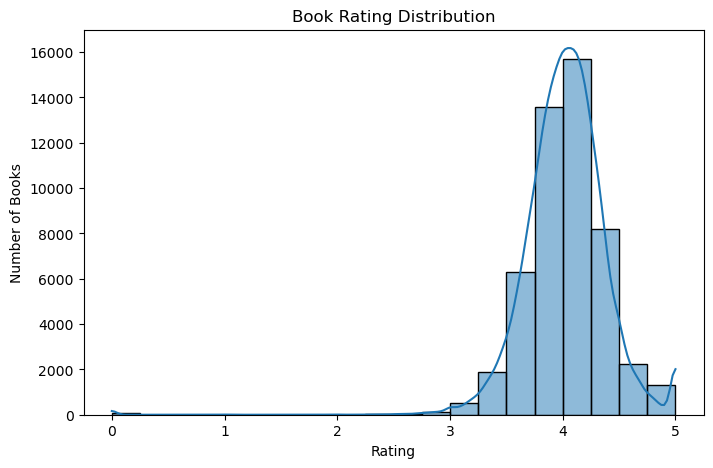

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(books["rating"].dropna(), bins=20, kde=True)
plt.title("Book Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.show()

In [10]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

books["combined_text"] = (
    books["title"].apply(clean_text) + " " +
    books["author"].apply(clean_text) + " " +
    books["genres_text"].apply(clean_text) + " " +
    books["description"].apply(clean_text)
)

books[["title", "combined_text"]].head()

,title,combined_text
0,The Hunger Games,the hunger games suzanne collins young adult fiction dystopia fantasy science fiction romance adventure teen post apocalyptic action winning means fame and fortune losing means certain death the h...
1,Harry Potter and the Order of the Phoenix,harry potter and the order of the phoenix j k rowling mary grandpr illustrator fantasy young adult fiction magic childrens adventure audiobook middle grade classics science fiction fantasy there i...
2,To Kill a Mockingbird,to kill a mockingbird harper lee classics fiction historical fiction school literature young adult historical novels read for school high school the unforgettable novel of a childhood in a sleepy ...
3,Pride and Prejudice,pride and prejudice jane austen anna quindlen introduction classics fiction romance historical fiction literature historical novels historical romance classic literature adult alternate cover edit...
4,Twilight,twilight stephenie meyer young adult fantasy romance vampires fiction paranormal paranormal romance supernatural teen urban fantasy about three things i was absolutely positive first edward was a ...


In [32]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

books["rating_score"] = scaler.fit_transform(
    books[["rating"]]
)

books[["title", "rating", "rating_score"]].head()

,title,rating,rating_score
0,The Hunger Games,4.33,0.866
1,Harry Potter and the Order of the Phoenix,4.50,0.900
2,To Kill a Mockingbird,4.28,0.856
3,Pride and Prejudice,4.26,0.852
4,Twilight,3.60,0.720


In [11]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=30000,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf.fit_transform(books["combined_text"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (49927, 30000)


In [12]:
knn = NearestNeighbors(
    n_neighbors=6,
    metric="cosine",
    algorithm="brute"
)

knn.fit(tfidf_matrix)

print("KNN model trained successfully.")

KNN model trained successfully.


In [35]:
# Normalize titles for easier searching
books["title_normalized"] = (
    books["title"]
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)


def recommend_books(book_title, n_recommendations=5):

    query = re.sub(
        r"[^a-zA-Z0-9\s]",
        " ",
        str(book_title).lower()
    )

    query = re.sub(r"\s+", " ", query).strip()

    # Exact title match
    matches = books[
        books["title_normalized"] == query
    ]

    # Partial title match
    if matches.empty:
        matches = books[
            books["title_normalized"].str.contains(
                query,
                na=False
            )
        ]

    if matches.empty:
        print("\n❌ Book not found!")
        print("Please enter another book title.")
        return None

    book_index = matches.index[0]

    # Get more neighbors because selected book itself
    # will also be included
    distances, indices = knn.kneighbors(
        tfidf_matrix[book_index],
        n_neighbors=n_recommendations + 1
    )

    recommendations = []

    for distance, index in zip(
        distances[0],
        indices[0]
    ):

        # Skip selected book
        if index == book_index:
            continue

        # Convert cosine distance to similarity
        content_similarity = 1 - distance

        # Get rating score
        rating_score = books.iloc[index]["rating_score"]

        # Hybrid final score
        final_score = (
            0.70 * content_similarity
            +
            0.30 * rating_score
        )

        recommendations.append({

            "Book Title":
                books.iloc[index]["title"],

            "Author":
                books.iloc[index]["author"],

            "Genres":
                books.iloc[index]["genres_text"],

            "Content Similarity":
                f"{content_similarity * 100:.2f}%",

            "Rating":
                f"{books.iloc[index]['rating']:.2f}",

            "Final Score":
                final_score

        })

    # Convert to DataFrame
    result = pd.DataFrame(recommendations)

    # Sort according to hybrid score
    result = result.sort_values(
        "Final Score",
        ascending=False
    )

    # Add rank
    result.insert(
        0,
        "Rank",
        range(1, len(result) + 1)
    )

    # Convert final score to percentage
    result["Final Score"] = (
        result["Final Score"] * 100
    ).round(2).astype(str) + "%"

    print("\n" + "=" * 80)
    print("📚 HYBRID BOOK RECOMMENDATION SYSTEM")
    print("=" * 80)

    print("\n🔎 Input Book:")
    print(f"   {books.iloc[book_index]['title']}")

    print("\n✍️ Author:")
    print(f"   {books.iloc[book_index]['author']}")

    print("\n" + "-" * 80)
    print(f"⭐ TOP {n_recommendations} RECOMMENDED BOOKS")
    print("-" * 80)

    display(result)

    print("\n💡 Recommendation Method:")
    print("   TF-IDF + KNN + Cosine Similarity + Rating")

    print("\n📊 Hybrid Score:")
    print("   70% Content Similarity + 30% Rating")

    print("=" * 80)

    return None

In [36]:
recommend_books("The Hunger Games", 5)


📚 HYBRID BOOK RECOMMENDATION SYSTEM

🔎 Input Book:
   The Hunger Games

✍️ Author:
   Suzanne Collins

--------------------------------------------------------------------------------
⭐ TOP 5 RECOMMENDED BOOKS
--------------------------------------------------------------------------------


,Rank,Book Title,Author,Genres,Content Similarity,Rating,Final Score
0,1,"SAMPLER ONLY: Catching Fire (The Hunger Games, #2)",Suzanne Collins,Dystopia Young Adult Science Fiction Fiction Post Apocalyptic Action Fantasy Coming Of Age Adventure,54.63%,4.52,65.36%
3,2,The Hunger Games Tribute Guide,Emily Seife (Goodreads Author),Young Adult Dystopia Fantasy Fiction Science Fiction Media Tie In Adventure Teen Guides Romance,47.43%,4.41,59.66%
1,3,Guide to The Hunger Games,"Caroline Carpenter, Stephanie Clarkson",Young Adult Science Fiction Dystopia,47.91%,4.34,59.58%
2,4,Mockingjay,Suzanne Collins,Young Adult Dystopia Fiction Fantasy Science Fiction Romance Adventure Teen Post Apocalyptic Science Fiction Fantasy,47.60%,4.04,57.56%
4,5,The Hunger Games Trilogy Boxset,"Suzanne Collins, Guillaume Fournier (Translator), Pilar Ramírez Tello (Goodreads Author) (Translator), Hanna Hörl (Illustrator), Sylke Hachmeister (Translator), Peter Klöss (Translator)",Young Adult Fiction Fantasy Dystopia Science Fiction Romance Adventure Teen Action Novels,43.47%,4.48,57.31%



💡 Recommendation Method:
   TF-IDF + KNN + Cosine Similarity + Rating

📊 Hybrid Score:
   70% Content Similarity + 30% Rating


In [37]:
recommend_books("Harry Potter and the Order of the Phoenix", 5)


📚 HYBRID BOOK RECOMMENDATION SYSTEM

🔎 Input Book:
   Harry Potter and the Order of the Phoenix

✍️ Author:
   J.K. Rowling, Mary GrandPré (Illustrator)

--------------------------------------------------------------------------------
⭐ TOP 5 RECOMMENDED BOOKS
--------------------------------------------------------------------------------


,Rank,Book Title,Author,Genres,Content Similarity,Rating,Final Score
0,1,Harry Potter and the Prisoner of Azkaban,"J.K. Rowling, Mary GrandPré (Illustrator)",Fantasy Young Adult Fiction Magic Childrens Adventure Middle Grade Audiobook Classics Science Fiction Fantasy,49.47%,4.57,62.05%
1,2,Harry Potter and the Chamber of Secrets,"J.K. Rowling, Mary GrandPré (Illustrator)",Fantasy Young Adult Fiction Magic Childrens Middle Grade Adventure Audiobook Classics Science Fiction Fantasy,48.55%,4.43,60.56%
2,3,Harry Potter and the Goblet of Fire,"J.K. Rowling, Mary GrandPré (Illustrator)",Fantasy Young Adult Fiction Magic Childrens Adventure Audiobook Middle Grade Classics Science Fiction Fantasy,44.20%,4.56,58.3%
3,4,"Harry Potter and the Order of the Phoenix (Harry Potter, #5, Part 1)",J.K. Rowling,Fantasy Fiction Young Adult Magic Childrens Adventure Middle Grade Classics Audiobook Novels,42.11%,4.62,57.2%
4,5,Harry Potter and the Half-Blood Prince,J.K. Rowling,Fantasy Young Adult Fiction Magic Childrens Adventure Audiobook Middle Grade Classics Science Fiction Fantasy,41.00%,4.57,56.12%



💡 Recommendation Method:
   TF-IDF + KNN + Cosine Similarity + Rating

📊 Hybrid Score:
   70% Content Similarity + 30% Rating


In [38]:
recommend_books("The Book Thief", 7)


📚 HYBRID BOOK RECOMMENDATION SYSTEM

🔎 Input Book:
   The Book Thief

✍️ Author:
   Markus Zusak (Goodreads Author)

--------------------------------------------------------------------------------
⭐ TOP 7 RECOMMENDED BOOKS
--------------------------------------------------------------------------------


,Rank,Book Title,Author,Genres,Content Similarity,Rating,Final Score
2,1,Kerri's War,Stephen Douglass (Goodreads Author),Thriller Romance Crime Amazon,19.76%,4.58,41.31%
1,2,My Family for the War,"Anne C. Voorhoeve, Tammi Reichel (Translator)",Historical Fiction Young Adult World War II War Historical Holocaust Fiction International Teen Family,20.31%,4.24,39.66%
5,3,Projekt 1065: A Novel of World War II,Alan Gratz,Historical Fiction Young Adult Historical Middle Grade World War II Fiction War Audiobook Adventure Childrens,18.12%,4.35,38.78%
4,4,Why Not-World,Alexei Maxim Russell (Goodreads Author),Fantasy Young Adult Dystopia Science Fiction Fantasy Fiction,19.00%,4.11,37.96%
6,5,Mother Night,Kurt Vonnegut Jr.,Fiction Classics Historical Fiction Literature War Novels Humor Science Fiction American 20th Century,18.01%,4.20,37.81%
3,6,Γαλήνη,"Ilias Venezis, Ηλίας Βενέζης",Fiction Greece Literature Classics Novels,19.03%,3.99,37.26%
0,7,عصير الكتب,علاء الديب,Nonfiction Books About Books,21.15%,3.53,35.98%



💡 Recommendation Method:
   TF-IDF + KNN + Cosine Similarity + Rating

📊 Hybrid Score:
   70% Content Similarity + 30% Rating
